In [2]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: C:\Users\Mystic\Desktop\ml-systems\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
CUDA available: False


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

a = torch.tensor([1.0, 2.0, 3.0], device=device)
b = torch.tensor([4.0, 5.0, 6.0], device=device)

result = a + b

print("Device:", result.device)
print("Result:", result)

Device: cpu
Result: tensor([5., 7., 9.])


In [4]:
w = torch.tensor(1.0, requires_grad=True)
x = torch.tensor(3.0)
y = torch.tensor(6.0)
prediction = w * x
loss = (prediction - y) ** 2

print("Prediction:", prediction.item())
print("Loss:", loss.item())
print("Before backward:", w.grad)

loss.backward()

print("After backward:", w.grad)

Prediction: 3.0
Loss: 9.0
Before backward: None
After backward: tensor(-18.)


In [6]:
learning_rate = 0.05

with torch.no_grad():
    w -= learning_rate * w.grad

w.grad = None

new_prediction = w * x
new_loss = (new_prediction - y) ** 2

print("New weight:", w.item())
print("New prediction:", new_prediction.item())
print("New loss:", new_loss.item())

New weight: 1.9000000953674316
New prediction: 5.700000286102295
New loss: 0.08999982476234436


In [7]:
# Training a weight over 30 iterations

In [10]:
w = torch.tensor(1.0, requires_grad=True)
x = torch.tensor(3.0)
y = torch.tensor(6.0)

learning_rate = 0.05
losses = []

for i in range(30):
    prediction = w*x
    loss = (prediction - y) ** 2

    losses.append(loss.item())
    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad

    w.grad = None

    if i%5 == 0:
        print(f"Epoch {i}: Weight = {w.item():.4f}, Loss = {loss.item():.6f}")

Epoch 0: Weight = 1.9000, Loss = 9.000000
Epoch 5: Weight = 2.0000, Loss = 0.000000
Epoch 10: Weight = 2.0000, Loss = 0.000000
Epoch 15: Weight = 2.0000, Loss = 0.000000
Epoch 20: Weight = 2.0000, Loss = 0.000000
Epoch 25: Weight = 2.0000, Loss = 0.000000


In [11]:
import matplotlib.pyplot as plt

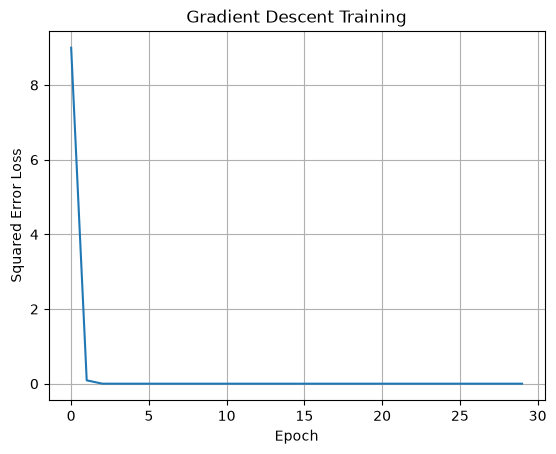

In [17]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Squared Error Loss")
plt.title("Gradient Descent Training")
plt.grid(True)
plt.show()